# Aula 7 — Consumo da Camada Gold pelo analista

Lê o Parquet publicado pelo dbt em `s3://gold/analytics/receita_mensal.parquet` diretamente no MinIO, sem abrir o `lakehouse.duckdb` do dbt.

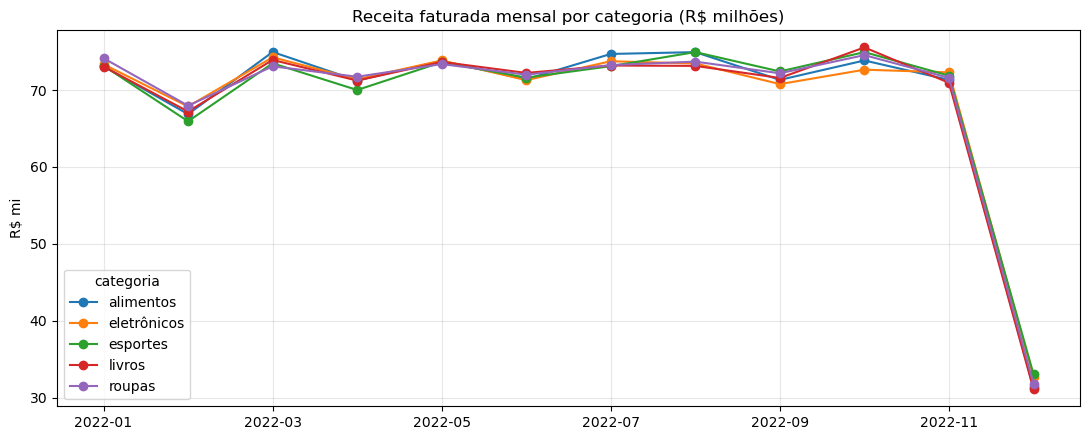

In [1]:
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("""CREATE SECRET minio (TYPE s3, KEY_ID 'minioadmin', SECRET 'minioadmin123',
               ENDPOINT 'host.docker.internal:9000', URL_STYLE 'path', USE_SSL false, REGION 'us-east-1')""")

receita = con.sql("""
    SELECT ano_mes, categoria, SUM(receita) / 1e6 AS receita_mi
    FROM 's3://gold/analytics/receita_mensal.parquet'
    GROUP BY ALL ORDER BY ano_mes
""").df()

pivot = receita.pivot(index="ano_mes", columns="categoria", values="receita_mi")
ax = pivot.plot(figsize=(11, 4.5), marker="o", linewidth=1.5)
ax.set_title("Receita faturada mensal por categoria (R$ milhões)")
ax.set_xlabel(""); ax.set_ylabel("R$ mi"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()